# Example: Build a Hidden Markov Model of Daily Stock Excess Growth Rate
In this example, we build a generator of `SPY` excess growth rates directly from the data. We bin the training observations, count transitions, and fit a Normal emission in each bin. We then compare simulated distributions and volatility clustering with the same training data, before and after adding jump episodes.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Fit a generator by binning and counting:__ Partition excess growth rates with a fitted Laplace distribution, count moves between bins, and fit a Normal emission in each bin.
> * __Simulate ordinary paths and jump episodes:__ Sample state sequences from the transition matrix, add runs of tail states, and draw excess growth rates from the states' emission distributions.
> * __Compare simulated paths with the training data:__ Examine growth-rate distributions and the autocorrelation of absolute growth rates, and explain what these in-sample checks establish.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We gathered a daily open-high-low-close dataset for each firm in the [S&P500](https://en.wikipedia.org/wiki/S%26P_500) from `01-03-2014` until `12-31-2024`, along with data for a few exchange-traded funds and volatility products during that time. 

Let's load the `original_dataset::Dict{String,DataFrame}` by calling [the `MyTrainingMarketDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) and remove firms that do not have the maximum number of trading days. The cleaned dataset $\mathcal{D}$ will be stored in the `dataset` variable.

In [2]:
original_dataset = MyTrainingMarketDataSet() |> x-> x["dataset"];

Not all tickers in our dataset have the maximum number of trading days for various reasons, e.g., acquisition or de-listing events. Let's collect only those tickers with the maximum number of trading days.

First, let's compute the number of records for a firm that we know has a maximum value, e.g., `AAPL`, and save that value in the `maximum_number_trading_days::Int64` variable:

In [3]:
maximum_number_trading_days = original_dataset["AAPL"] |> nrow;

Now, let's iterate through our data and collect only tickers with `maximum_number_trading_days` records. Save that data in the `dataset::Dict{String,DataFrame}` variable:

In [4]:
dataset = Dict{String,DataFrame}();
for (ticker,data) ∈ original_dataset
    if (nrow(data) == maximum_number_trading_days)
        dataset[ticker] = data;
    end
end
dataset;

Finally, let's get a list of the firms in our cleaned dataset (and sort them alphabetically). We store the sorted firm ticker symbols in the `list_of_tickers::Array{String,1}` variable.

In [5]:
list_of_tickers = keys(dataset) |> collect |> sort; # list of firm "ticker" symbols in alphabetical order

### Constants and Parameters
Let's define some constants and parameters that we will use in this example. See the comment lines next to each variable for a description of its purpose, units, permissible values, etc.

In [6]:
Δt = 1.0 / 252.0; # one trading day, expressed in years
risk_free_rate = 0.043; # constant annual risk-free growth rate (1/yr)
myticker = "SPY"; # ticker to model
random_seed = 5660; # reproducible state sequences and emissions
Random.seed!(random_seed);

### Growth Rate Calculation
We compute the daily excess growth rate from the volume-weighted average price $S_t$:
$$
R_t = \frac{1}{\Delta t}\ln\left(\frac{S_t}{S_{t-1}}\right)-r_f.
$$
Here $\Delta t$ is the time step in years and $r_f$ is the constant risk-free growth rate in `risk_free_rate`. Each $R_t$ has units 1/yr. We store the series for all firms in `all_firms_excess_return_matrix::Array{Float64,2}`.

In [7]:
all_firms_excess_return_matrix = log_growth_matrix(dataset, list_of_tickers, 
    Δt = Δt, risk_free_rate = risk_free_rate);

The growth rate that we will model will be stored in the `Rᵢ::Array{Float64,1}` variable for firm `myticker::String`. 

In [8]:
Rᵢ = findfirst(x->x==myticker, list_of_tickers) |> i-> all_firms_excess_return_matrix[:,i];

___

## Task 1: Construct the States and Transition Matrix
In this task, we assign each observed excess growth rate to a bin and estimate the transition probabilities by counting moves between bins. We also set up the discrete state labels used by the simulator.

> __Idea:__
>
> __States:__ We number the bins from the most negative growth rates (state 1) to the most positive (state $N$). The bin of a training observation is known from its value.
>
> __Distribution:__ We fit a Laplace distribution and cut it into bins of equal probability under that fitted distribution. Counting consecutive observations in each pair of bins gives the transition matrix $\hat{\mathbf{P}}$.

The `number_of_states` variable sets the number of bins. We store their labels in `states`:

In [9]:
number_of_states = 100; # number of bins in the excess growth rate
states = range(1,stop=number_of_states) |> collect;

During fitting, the bins give an observed state sequence. During simulation, the state is internal to the generator and its Normal emission produces the growth rate we observe.

The package's discrete simulator returns state labels using $\mathbf{E}=\mathbf{I}$. The decode operation below then draws a growth rate from the Normal emission of the returned state:

In [10]:
E = diagm(ones(number_of_states)); # emission matrix, identity matrix of size `number_of_states` x `number_of_states`

### Estimate the transition matrix $\hat{\mathbf{P}}$ from market data
To estimate the transition matrix $\hat{\mathbf{P}}$, we'll estimate the transition probabilities from the excess return data calculated in the `Prerequisites` section and saved in the `Rᵢ` variable. 

In [11]:
in_sample_dataset = Rᵢ[1:(maximum_number_trading_days-1)] # set of excess return

2766-element Vector{Float64}:
 -0.6275399670984476
  0.8396262386945091
  0.16299199696256234
 -0.01113369193943612
  0.25733420862761536
 -1.378988774125505
  0.32151271641711465
  2.0000590819913135
 -0.32304976380825395
 -0.436880737916184
 -0.07669593758943921
  0.3983882778085264
 -2.00015091651247
  ⋮
 -0.5437518800661111
  0.9021508357217608
 -1.0148344267279927
 -3.8191858909074563
 -3.0876707822786664
  0.233632780780899
  1.6080264971962088
  2.6888092382740747
  0.7444999191864144
 -2.7618744641560036
 -2.505501843730946
 -0.9633409493684527

We fit a Laplace distribution to `Rᵢ` to choose the bin boundaries. The [`fit_mle(...)` function](https://juliastats.org/Distributions.jl/stable/fit/#Distributions.fit_mle-Tuple{Any,%20Any}) estimates the distribution by maximum likelihood. We save it in `d` and plot its cumulative and complementary probabilities:

In [12]:
d = fit_mle(Laplace, Rᵢ); # use the *full* data set to establish the cutoff's

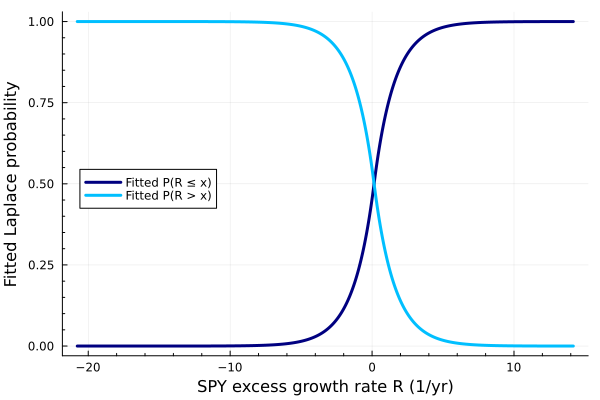

In [13]:
let

    # regions of return -
    number_of_samples = 1000;
    minimum_obs_growth = minimum(in_sample_dataset);
    maximum_obs_growth = maximum(in_sample_dataset);
    RA = range(minimum_obs_growth,stop = maximum_obs_growth, length = number_of_samples) |> collect;

    X = Array{Float64,2}(undef, number_of_samples,2);
    for i ∈ eachindex(RA)
    
        X[i,1] = RA[i];
        X[i,2] = cdf(d, RA[i]);
    end

    plot(X[:,1], X[:,2], lw=3, c=:navy, label="Fitted P(R ≤ x)", xminorticks=5, yminorticks=5)
    plot!(X[:,1], 1 .- X[:,2], lw=3, c=:deepskyblue1, label="Fitted P(R > x)", legend=:left)

    xlabel!("$(myticker) excess growth rate R (1/yr)", fontsize=18);
    ylabel!("Fitted Laplace probability", fontsize=18);
end

Next, we generate the percentile cutoffs that we use to establish the bounds that correspond to each category of return, i.e., `super bad` or `super good`, etc.

In [14]:
percentage_cutoff = range(0.0,stop=1.0,length=(number_of_states+1)) |> collect;

Now that we have the cutoffs, compute the lower and upper bound for each potential category. To do this, we'll use the [quantile function](https://juliastats.org/Distributions.jl/stable/univariate/#Statistics.quantile-Tuple{UnivariateDistribution,%20Real}) exported by the [Distributions.jl package](https://github.com/JuliaStats/Distributions.jl). For a given `0 ≤ q ≤ 1`, `quantile(d, q)` is the smallest value `x` 
for which `cdf(d, x) ≥ q`.

In [15]:
bounds = let

    # initialize -
    bounds = Array{Float64,2}(undef, number_of_states, 3)
    
    # compute bounds -
    for s ∈ states
        bounds[s,1] = quantile(d,percentage_cutoff[s])
        bounds[s,2] = quantile(d,percentage_cutoff[s+1])
        bounds[s,3] = s
    end
    bounds; # return bounds
end

100×3 Matrix{Float64}:
 -Inf       -5.55445    1.0
  -5.55445  -4.54514    2.0
  -4.54514  -3.95474    3.0
  -3.95474  -3.53584    4.0
  -3.53584  -3.21091    5.0
  -3.21091  -2.94543    6.0
  -2.94543  -2.72097    7.0
  -2.72097  -2.52653    8.0
  -2.52653  -2.35503    9.0
  -2.35503  -2.20161   10.0
  -2.20161  -2.06283   11.0
  -2.06283  -1.93613   12.0
  -1.93613  -1.81958   13.0
   ⋮                  
   2.21998   2.34667   89.0
   2.34667   2.48546   90.0
   2.48546   2.63888   91.0
   2.63888   2.81038   92.0
   2.81038   3.00482   93.0
   3.00482   3.22928   94.0
   3.22928   3.49476   95.0
   3.49476   3.81969   96.0
   3.81969   4.23859   97.0
   4.23859   4.82899   98.0
   4.82899   5.8383    99.0
   5.8383   Inf       100.0

Now that we have the category bounds, let's take the excess return data and determine which state an excess return observation corresponds to. For each sample in the `in_sample_dataset`:

Classify the sample value into one of the possible categories. Let `state = 1` equal the worst return, and `state = number_of_states` equal the best return. Save these results in the `encoded_in_sample` array:

In [16]:
encoded_in_sample = let

    # initialize -
    encoded_in_sample = Array{Int64,1}();

    for i ∈ eachindex(in_sample_dataset)
        value = in_sample_dataset[i];

        class_index = 1;
        for s ∈ states
            if (bounds[s,1] ≤ value && value < bounds[s,2])
                class_index = s;
                break;
            end
        end
        push!(encoded_in_sample, class_index);
    end
    encoded_in_sample; # return
end

2766-element Vector{Int64}:
 30
 70
 51
 46
 54
 18
 56
 87
 37
 34
 44
 59
 12
  ⋮
 32
 71
 23
  4
  6
 54
 82
 92
 67
  7
  9
 24

In the matrix $\mathbf{P}$ compute the `counts` for transition from state `i` to state `j`:

In [17]:
P = let

    # initialize -
    P = zeros(number_of_states, number_of_states)
    number_insample = length(encoded_in_sample);
    
    # main loop -
    for i ∈ 2:number_insample
        start_index = encoded_in_sample[i-1];
        stop_index = encoded_in_sample[i];
        P[start_index,stop_index] += 1;
    end
    P; # return
end

100×100 Matrix{Float64}:
 8.0  3.0  2.0  1.0  2.0  2.0  0.0  0.0  …  1.0  1.0  2.0  0.0  0.0  0.0  2.0
 3.0  2.0  1.0  0.0  0.0  1.0  0.0  0.0     1.0  0.0  1.0  0.0  1.0  0.0  1.0
 1.0  0.0  0.0  0.0  2.0  0.0  1.0  1.0     0.0  1.0  0.0  0.0  0.0  1.0  0.0
 4.0  1.0  2.0  0.0  0.0  2.0  0.0  1.0     0.0  1.0  0.0  1.0  1.0  0.0  1.0
 2.0  0.0  1.0  0.0  0.0  0.0  0.0  3.0     0.0  0.0  0.0  0.0  0.0  0.0  2.0
 1.0  1.0  1.0  0.0  1.0  0.0  0.0  0.0  …  0.0  1.0  1.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  2.0  0.0  1.0  2.0  1.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 2.0  1.0  1.0  0.0  1.0  1.0  1.0  0.0     0.0  0.0  1.0  0.0  0.0  0.0  0.0
 1.0  2.0  0.0  0.0  1.0  1.0  0.0  1.0     1.0  0.0  0.0  1.0  0.0  0.0  0.0
 1.0  1.0  1.0  1.0  0.0  0.0  0.0  1.0     0.0  0.0  1.0  0.0  0.0  1.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  1.0  0.0  2.0  0.0
 1.0  0.0  0.0  0.0  1.0  1.0  1.0  0.0     0.0  2.0  1.0  0.0  0.0  0.0  0.0
 2.0  1.0  0.0  1.0  2.0  0.0  0.0  0.0

From the `counts` matrix $\mathbf{P}$, compute the transition probability matrix $\hat{\mathbf{P}}$::`Array{Float64,2}` by normalizing each row of the `counts` matrix by the sum of the row:

In [18]:
P̂ = let

    # initialize -
    P̂ = zeros(number_of_states, number_of_states)
    for row ∈ states
        Z = sum(P[row,:]);
        for col ∈ states
            P̂[row,col] = (1/Z)*P[row,col]
        end
    end
    P̂; # return
end

100×100 Matrix{Float64}:
 0.170213   0.0638298  0.0425532  …  0.0        0.0        0.0425532
 0.107143   0.0714286  0.0357143     0.0357143  0.0        0.0357143
 0.0434783  0.0        0.0           0.0        0.0434783  0.0
 0.133333   0.0333333  0.0666667     0.0333333  0.0        0.0333333
 0.0689655  0.0        0.0344828     0.0        0.0        0.0689655
 0.0434783  0.0434783  0.0434783  …  0.0        0.0        0.0
 0.0        0.0        0.0           0.0        0.0        0.0
 0.0606061  0.030303   0.030303      0.0        0.0        0.0
 0.037037   0.0740741  0.0           0.0        0.0        0.0
 0.030303   0.030303   0.030303      0.0        0.030303   0.0
 0.0        0.0        0.0        …  0.0        0.0869565  0.0
 0.0434783  0.0        0.0           0.0        0.0        0.0
 0.0714286  0.0357143  0.0           0.0        0.0        0.0
 ⋮                                ⋱                        
 0.0        0.0        0.0344828     0.0344828  0.0        0.0
 0.037037

___

## Task 2: Simulate the Hidden Markov Model (HMM)
To do the simulation, we first build a [`MyHiddenMarkovModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/markov/#VLQuantitativeFinancePackage.MyHiddenMarkovModel), which holds the data for our Markov model. We use a [`build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/markov/#VLQuantitativeFinancePackage.build-Tuple{Type{MyHiddenMarkovModel},%20NamedTuple}), which takes information about the `states,` the estimated transition matrix $\hat{\mathbf{P}}$, and the emission matrix $\mathbf{E}$ and returns a [`MyHiddenMarkovModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/markov/#VLQuantitativeFinancePackage.MyHiddenMarkovModel), which we save in the `model` variable.

In [19]:
model = build(MyHiddenMarkovModel, (
    states = states, # states
    T = P̂, # transition matrix (estimate)
    E = E # emission matrix
));

### Generate the stationary distribution from the estimated $\hat{\mathbf{P}}$ matrix
Generate the stationary distribution for the estimated transition matrix $\hat{\mathbf{P}}$ and use it to construct a [Categorical distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Categorical) representing the stationary distribution. Save the [Categorical distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Categorical) in the `π̄` variable:

In [20]:
power_value = 50;
π̄ = (P̂^power_value) |> tmp -> Categorical(tmp[1,:]); # TODO: compute the stationary distribution (approx value is ok)

### Generate hypothetical growth-rate sequences
We generate `number_of_paths` sequences, each with as many steps as the training growth-rate series. Each path starts from a draw from the stationary distribution `π̄`.

The call `model(start_state, number_of_steps)` returns the sampled state labels. We store them in `encoded_archive::Array{Int64,2}`, with trading days on the rows and paths on the columns:

In [21]:
encoded_archive, number_of_paths = let

    number_of_paths = 100;
    number_of_steps = length(in_sample_dataset);
    encoded_archive = Array{Int64,2}(undef, number_of_steps, number_of_paths);
    
    for i ∈ 1:number_of_paths
        start_state = rand(π̄);
        tmp = model(start_state, number_of_steps) # wow! That's fancy. Isn't model a type??
        for j ∈ 1:number_of_steps
            encoded_archive[j,i] = tmp[j,1]
        end
    end
    (encoded_archive, number_of_paths)
end

([25 15 … 17 2; 98 57 … 87 94; … ; 26 81 … 24 72; 98 10 … 66 26], 100)

In [22]:
actual_sample_bounds = copy(bounds);
actual_sample_bounds[1,1] = minimum(in_sample_dataset);
actual_sample_bounds[end,2] = maximum(in_sample_dataset)
actual_sample_bounds

100×3 Matrix{Float64}:
 -20.7731   -5.55445    1.0
  -5.55445  -4.54514    2.0
  -4.54514  -3.95474    3.0
  -3.95474  -3.53584    4.0
  -3.53584  -3.21091    5.0
  -3.21091  -2.94543    6.0
  -2.94543  -2.72097    7.0
  -2.72097  -2.52653    8.0
  -2.52653  -2.35503    9.0
  -2.35503  -2.20161   10.0
  -2.20161  -2.06283   11.0
  -2.06283  -1.93613   12.0
  -1.93613  -1.81958   13.0
   ⋮                  
   2.21998   2.34667   89.0
   2.34667   2.48546   90.0
   2.48546   2.63888   91.0
   2.63888   2.81038   92.0
   2.81038   3.00482   93.0
   3.00482   3.22928   94.0
   3.22928   3.49476   95.0
   3.49476   3.81969   96.0
   3.81969   4.23859   97.0
   4.23859   4.82899   98.0
   4.82899   5.8383    99.0
   5.8383   14.1795   100.0

### Decode operation
To turn the state $s\in\mathcal{S}$ back into an excess return value, we need to __decode__ the state. To do this, let's construct a [Normal distribution](https://en.wikipedia.org/wiki/Normal_distribution) describing the observed return values associated with each state in the `encoded_in_sample` dataset.

We collect the observed excess return samples associated with a particular state $s$, store them in a `tmp` array, and use [Maximum Likelihood Estimation](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation) to estimate a [Normal distribution exported from the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal)

In [23]:
decode_distribution_model = Dict{Int,Normal}()
for s ∈ states

    # what indexes correspond to state s
    index_collection_state_s = findall(x-> x == s, encoded_in_sample);
    tmp = Array{Float64,1}();
    for i ∈ index_collection_state_s
        decoded_value = Rᵢ[i];
        push!(tmp, decoded_value);
    end
    decode_distribution_model[s] = fit_mle(Normal,tmp);
end
decode_distribution_model;

Then, generate a random value for the excess return by sampling the appropriate [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal). We develop `number_of_paths` trajectories, each containing `number_of_steps` values. We store these values in the `decoded_archive` variable:

In [24]:
in_sample_decoded_archive = let

    # initialize -
    number_of_steps = length(in_sample_dataset);
    in_sample_decoded_archive = Array{Float64,2}(undef, number_of_steps, number_of_paths);
    
    for i ∈ 1:number_of_paths
        for j ∈ 1:number_of_steps
            s = encoded_archive[j,i];
            in_sample_decoded_archive[j,i] =  decode_distribution_model[s] |> d -> rand(d)
        end
    end
    in_sample_decoded_archive # actual excess growth value
end

2766×100 Matrix{Float64}:
  -0.890194   -1.71746     0.721494   -0.400721   …  -1.45972      -5.3205
   4.51615     0.336201   -0.45135     0.190557       2.04957       3.15511
  -0.037105    0.427743   -2.74891     1.26712        1.35533       0.437583
   0.244968    0.238674   -0.900438    0.715986       1.30452      -1.97213
   1.0167      1.59542     2.73163    -0.192484      -2.21427      -3.36199
   2.17721     0.143813    1.82873     1.02887    …   0.246672     -2.53949
  -0.192553   -0.118117    1.29778    -0.322047      -1.38587       1.27864
  -3.85111     0.708537    0.691344    0.378223      -1.90102      -1.16927
 -10.6337     -0.111196   -0.843398   -0.718415      -0.871291     -0.371777
   3.48552    -1.61821    -0.960513   -0.369216       0.000367093   5.20215
   0.318168   -2.65218    -1.03922     0.725292   …   1.11681       1.14318
   1.47976     0.0237476   0.442752   -1.19244        2.05609      -0.104653
   3.11525     1.22761     1.23068    -0.223834      -0.1480

### Visualize an example in-sample return trajectory
`Unhide` the code block to see how we plotted the observed (red) and simulated (blue) excess growth rate values for a randomly selected sample model generated sample path.

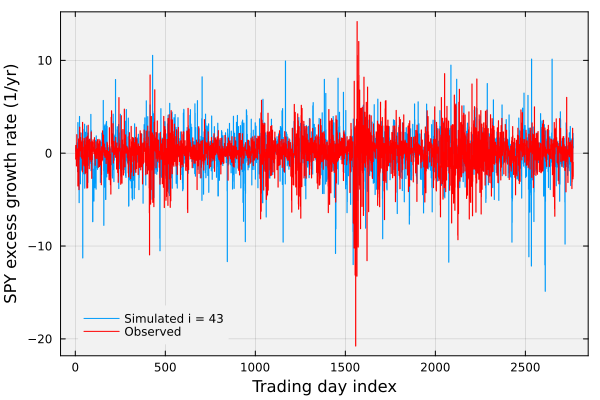

In [25]:
let
    index_to_plot = rand(1:number_of_paths);
    plot(in_sample_decoded_archive[:,index_to_plot], linetype=:steppost, label="Simulated i = $(index_to_plot)", 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(in_sample_dataset, linetype=:steppost, c=:red, label="Observed")
    xlabel!("Trading day index", fontsize=18)
    ylabel!("$(myticker) excess growth rate (1/yr)", fontsize=18)
end

`Unhide` the code block below to see how we plotted the observed and simulated excess annual growth rate distribution for the in-sample data.

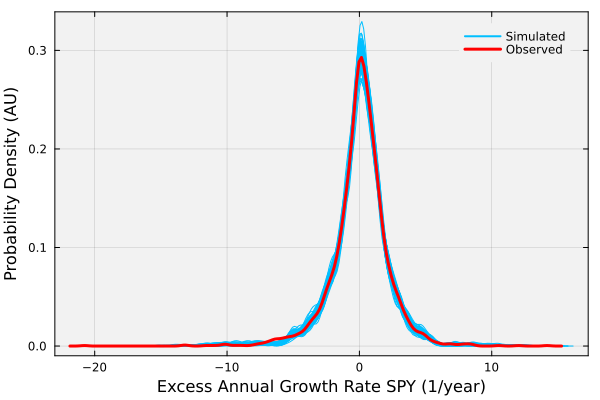

In [26]:
let
    q = plot(); 
    density!(in_sample_decoded_archive[:,1], lw=2, c=:deepskyblue1, label="Simulated", 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    for i ∈ 2:number_of_paths
        density!(in_sample_decoded_archive[:,i], lw=1, c=:deepskyblue1, label="")
    end
    density!(in_sample_dataset, c=:red, lw=3, label="Observed")
    xlabel!("Excess Annual Growth Rate $(myticker) (1/year)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
    current()
end

### Compare the in-sample distributions
We compare the real and simulated growth-rate distributions with the Kolmogorov–Smirnov statistic. Consecutive days are dependent, so we use the test as a descriptive check of distributional similarity.

> __Test:__ The null hypothesis is that the two samples come from the same distribution. A p-value above the chosen cutoff means we fail to reject that hypothesis.

This is an in-sample comparison: the same observations fitted the generator. Let's examine one simulated path:

In [27]:
ApproximateTwoSampleKSTest(in_sample_dataset,in_sample_decoded_archive[:,rand(1:number_of_paths)])

Approximate two sample Kolmogorov-Smirnov test
----------------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.0151844

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.9073

Details:
    number of observations:   [2766,2766]
    KS-statistic:              0.564687539577047


Next, we repeat the comparison for every path. We report the fraction whose p-value exceeds `pvalue_cutoff`. This summarizes agreement with the training distribution.

In [28]:
let
    pvalue_cutoff = 0.05; # cutoff 
    pass_counter = 0;
    for i ∈ 1:number_of_paths
        test_value = ApproximateTwoSampleKSTest(in_sample_dataset,in_sample_decoded_archive[:,i]) |> pvalue
        if (test_value > pvalue_cutoff)
            pass_counter += 1 # we pass (fail to reject) x and y are from the same distribution
        end
    end
    println("Pass percentage: $((pass_counter/number_of_paths)*100)%")
end

Pass percentage: 98.0%


___

## Task 3: What Does Our Jump Model Do?
In this task, we add episodes of extreme states and examine their effect on the simulated growth rates. With no episode under way, an episode starts with probability $\epsilon$ at each step. Its length is drawn from a Poisson distribution with mean $\lambda$ trading days.

On each episode day, the simulator draws from the five most negative states with probability 0.52 and from the five most positive states otherwise. An episode can contain moves of both signs.

The [`MyHiddenMarkovModelWithJumps` type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/markov/#VLQuantitativeFinancePackage.MyHiddenMarkovModelWithJumps) holds the transition and emission matrices with these jump settings. We save the model in `jump_model`:

In [29]:
jump_model = let
    
    model = build(MyHiddenMarkovModelWithJumps, (
        states = states,
        T = P̂, 
        E = E,
        ϵ = 0.0001, # episode-start probability per step when no episode is active
        λ = 63, # mean episode length (trading days)
    ));

    model;
end;

__Sample__: Next, we sample the `jump_model::MyHiddenMarkovModelWithJumps` model. Sampling the model results in the `encoded_archive_with_jumps::Array{Float64,2}` array, which holds sample paths (alternative futures) on the columns and time steps on the rows.

In [30]:
encoded_archive_with_jumps, jump_indicator_archive = let
    
    # initialize -
    number_of_steps = length(in_sample_dataset);
    number_of_paths = 100;
    encoded_archive = Array{Int64,2}(undef, number_of_steps, number_of_paths);
    jump_indicator_archive = Array{Int64,2}(undef, number_of_steps, number_of_paths);
    
    
    for i ∈ 1:number_of_paths
        start_state = rand(π̄);        
        tmp = jump_model(start_state, number_of_steps)
        for j ∈ 1:number_of_steps
            encoded_archive[j,i] = tmp[j,1]
            jump_indicator_archive[j,i] = tmp[j,2]
        end
    end
    (encoded_archive, jump_indicator_archive)
end;

__Which paths contain an episode?__ The `jump_indicator_archive` records a `1` on each episode day and `0` on an ordinary day. We collect the indices of paths containing an episode in `jump_trial_index_set` for the plots below.

In [31]:
jump_trial_index_set = let
    has_jumps_flag = any(x->x==1, jump_indicator_archive);
    jump_trial_index_set = Set{Int64}();
    if (has_jumps_flag == false)
        println("No jumps were detected in the simulated paths.")
    end;

    for i ∈ 1:number_of_paths
        for j ∈ axes(jump_indicator_archive, 1)
            if (jump_indicator_archive[j,i] == 1)
                push!(jump_trial_index_set, i);
            end
        end
    end
    println("Number of paths with at least one jump event: $(length(jump_trial_index_set)) out of $number_of_paths total paths.")

    jump_trial_index_set;
end;

Number of paths with at least one jump event: 21 out of 100 total paths.


__Decode__: We then decode the encoded states and save the decoded values in the `in_sample_decoded_archive_with_jumps::Array{Float64,2}` array. Each row is a return value at the time step, while each column is a sample path, i.e., an alternative universe in which our process is running

In [32]:
in_sample_decoded_archive_with_jumps = let

    # initialize -
    number_of_steps = length(in_sample_dataset);
    in_sample_decoded_archive = Array{Float64,2}(undef, number_of_steps, number_of_paths);
    
    for i ∈ 1:number_of_paths
        for j ∈ 1:number_of_steps
            s = encoded_archive_with_jumps[j,i];
            in_sample_decoded_archive[j,i] =  decode_distribution_model[s] |> d -> rand(d)
        end
    end
    in_sample_decoded_archive # actual excess growth value
end;

In [33]:
in_sample_decoded_archive_with_jumps

2766×100 Matrix{Float64}:
 -0.101988    7.15172     1.43597    -0.440483    …   1.58295      -0.379062
 -0.732216    1.43938     0.321248    3.41224         0.151265      2.34677
 -0.217408   -0.371311   -0.134056   -2.57279         0.0531728    -3.24224
 -1.48246    -0.568328   -1.47538     0.00233551     -1.0215        1.55219
  0.244513   -0.658692    0.256713   -2.82389         2.09311       1.1255
  1.2193      1.45453     2.90568    -2.84035     …  -3.05275       1.39743
  0.557782   -0.26003     4.9752     -1.52197         3.43773      -0.701011
  2.68433    -0.551816    1.17712    -0.0308498       0.129788     -0.361401
  1.925      -0.733155   -0.100631   -1.30669        -2.28262       0.769933
 -1.79919    -0.481275    0.404382   -0.996567        1.21312      -0.893651
  1.58162     0.974701   -0.185671    0.267646    …  -0.108129      1.13152
  3.78018    -2.48019     1.64922     1.59677         0.249632     -0.425941
 -1.70838     0.412868    0.0331026  -0.833515        1.7

`Unhide` the code block below to see how we plotted the observed and simulated excess annual growth rate distribution for the in-sample data. These simulated returns are generated using the jump model.

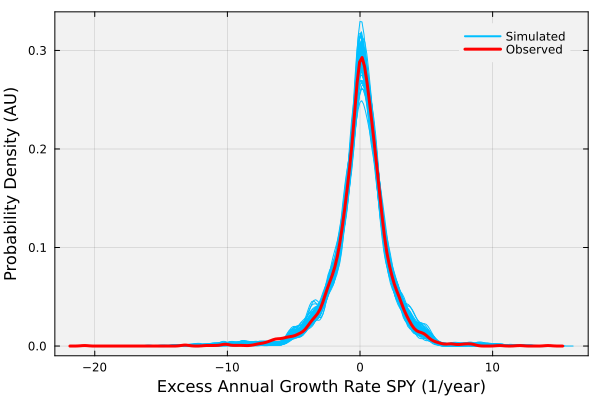

In [34]:
let
    q = plot(); 
    density!(in_sample_decoded_archive_with_jumps[:,1], lw=2, c=:deepskyblue1, label="Simulated", 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    for i ∈ 2:number_of_paths
        density!(in_sample_decoded_archive_with_jumps[:,i], lw=1, c=:deepskyblue1, label="")
    end
    density!(in_sample_dataset, c=:red, lw=3, label="Observed")
    xlabel!("Excess Annual Growth Rate $(myticker) (1/year)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
    current()
end

### Compare the jump-model distributions
We repeat the same descriptive Kolmogorov–Smirnov comparison for all jump-model paths. Some paths contain episodes and others do not. The fraction above the p-value cutoff summarizes the whole simulated population.

In [35]:
let
    pvalue_cutoff = 0.05; # 95% cutoff
    pass_counter = 0;
    for i ∈ 1:number_of_paths
        test_value = ApproximateTwoSampleKSTest(in_sample_dataset,in_sample_decoded_archive_with_jumps[:,i]) |> pvalue
        if (test_value > pvalue_cutoff)
            pass_counter += 1 # we pass (fail to reject) x and y are from the same distribution
        end
    end
    println("Pass percentage: $((pass_counter/number_of_paths)*100)%")
end

Pass percentage: 99.0%


### Visualize a path containing an episode
`Unhide` the code block below to see how we plotted the observed excess growth rates and the first simulated path containing an episode. We select that path from `jump_trial_index_set`.

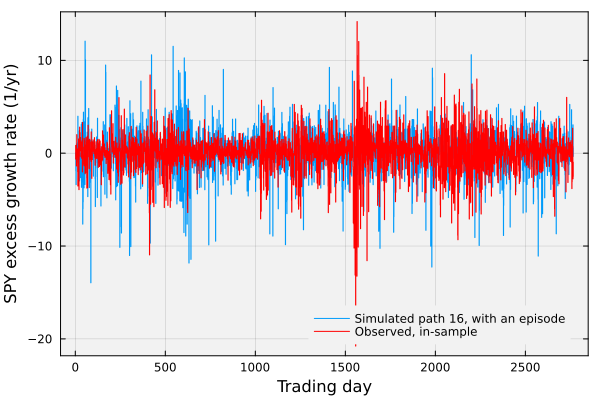

In [36]:
let
    # select a path whose indicators show an episode -
    index_to_plot = first(sort(collect(jump_trial_index_set)));
    plot(in_sample_decoded_archive_with_jumps[:,index_to_plot], linetype=:steppost,
        label="Simulated path $(index_to_plot), with an episode", bg="gray95",
        background_color_outside="white", framestyle=:box, fg_legend=:transparent);
    plot!(in_sample_dataset, linetype=:steppost, c=:red, label="Observed, in-sample");
    xlabel!("Trading day", fontsize=18);
    ylabel!("$(myticker) excess growth rate (1/yr)", fontsize=18);
end

### Volatility clustering of the simulated dataset
We measure volatility clustering with the autocorrelation of the absolute excess growth rate. Positive values at longer lags mean that large moves tend to follow large moves over those time scales.

`Unhide` the code block below to compare the training data with the same simulated path containing an episode. The dashed lines are the approximate 95% white-noise benchmark, $\pm 1.96/\sqrt{T}$, where $T$ is the number of observations.

Compare how long the two autocorrelations remain positive. This selected path shows what an episode can do; the distribution check above includes every path.

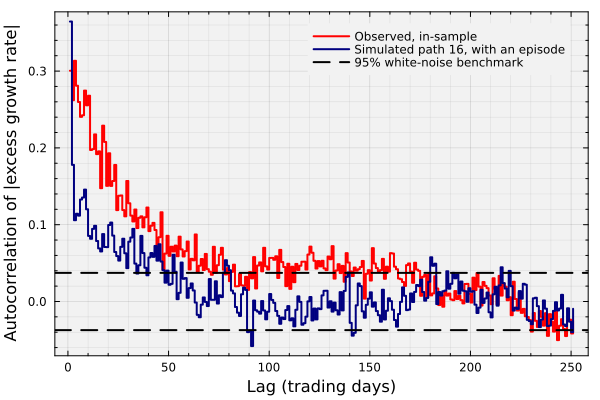

In [37]:
let
    # use the same path containing an episode as in the trajectory plot -
    random_index = first(sort(collect(jump_trial_index_set)));
    number_of_lags = min(251, length(in_sample_dataset) - 1);
    τ = 1:number_of_lags;
    AC_observed = autocor(abs.(in_sample_dataset), τ);
    AC_simulation = autocor(abs.(in_sample_decoded_archive_with_jumps[:,random_index]), τ);
    band = 1.96 / sqrt(length(in_sample_dataset)); # white-noise benchmark from the observation count

    plot(τ, AC_observed, label="Observed, in-sample", linetype=:steppost,
        bg="gray95", background_color_outside="white", framestyle=:box,
        fg_legend=:transparent, c=:red, lw=2, xminorticks=true, yminorticks=true, minorgrid=true);
    plot!(τ, AC_simulation, c=:navy, lw=2, label="Simulated path $(random_index), with an episode", linetype=:steppost);
    hline!([band, -band], label=["95% white-noise benchmark" ""], lw=2, c=:black, ls=:dash);
    xlabel!("Lag (trading days)", fontsize=18);
    ylabel!("Autocorrelation of |excess growth rate|", fontsize=18);

    # checks -
    @assert any(jump_indicator_archive[:,random_index] .== 1) "the selected path must contain an episode"
    @assert length(in_sample_dataset) == size(in_sample_decoded_archive_with_jumps, 1) "match the observed and simulated horizons"
    @assert band == 1.96 / sqrt(size(in_sample_decoded_archive_with_jumps, 1)) "use the number of observations in the band"

    # return -
    current()
end

#### Save the HMM model and other data to a file
Later, we'll use the hidden Markov Model (HMM) we developed here. Let's save the model to disk to save some time later on. Use the [save(...) method exported by the JLD2.jl package](https://github.com/JuliaIO/JLD2.jl.git) to write a [model file in HDF5 binary format](https://en.wikipedia.org/wiki/Hierarchical_Data_Format). First, we specify a `path` in the `path_to_save_file` variable:

In [38]:
path_to_save_file = joinpath(_PATH_TO_DATA,"HMM-WJ-$(myticker)-N-$(number_of_states)-daily-aggregate.jld2");

Then we write an [`HDF5 binary file`](https://en.wikipedia.org/wiki/Hierarchical_Data_Format) holding our data to the location specified by `path_to_save_file`. We use the [save(...) function exported by the JLD2.jl package to write a binary save file](https://github.com/JuliaIO/JLD2.jl.git) (later we'll use the `load(...)` function to reload this data):

In [39]:
save(path_to_save_file, Dict("model"=>model, "jump_model" => jump_model, 
        "risk_free_rate" => risk_free_rate,
        "number_of_states" => number_of_states,
        "decode"=>decode_distribution_model, "stationary"=>π̄, 
        "insampledataset"=>in_sample_dataset, "encoded_archive" => encoded_archive, "encoded_archive_with_jumps" => encoded_archive_with_jumps,
        "in_sample_decoded_archive_with_jumps" => in_sample_decoded_archive_with_jumps, 
        "in_sample_decoded_archive" => in_sample_decoded_archive));

___

## Summary
In this example, we built a generator of excess growth rates from binned observations, sampled it with and without jump episodes, and compared the simulated paths with the training data.

> __Key Takeaways:__
>
> * __Binning and counting:__ We partitioned excess growth rates with a fitted Laplace distribution and counted transitions between the observed bins. We fitted a Normal emission in each bin to turn simulated state labels into growth rates.
> * __Distribution checks:__ We compared simulated growth-rate distributions with the same observations used for fitting. The Kolmogorov–Smirnov comparisons described their agreement with the training distribution.
> * __Jump episodes:__ We added runs of tail states and selected a path whose indicators confirmed an episode. Comparing its absolute-growth autocorrelation with the data showed how the episode changed volatility clustering on that path.

These in-sample checks help us identify which features of the training series the generator reproduces.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___